# What Frustrates Toy Blast & Toon Blast Players? A Google Play Review Analysis

**Author:** Dogukan Sardag

In my [Cookie Cats A/B test analysis](https://github.com/dsardag/cookie_cats_ab_test), an earlier forced break (gate) led to *higher* retention. My hypothesis was that breaks protect players from burning out.

This project looks at the player side of the same question, using Peak's own games. **What do unhappy players actually complain about?** Is it waiting for lives, difficulty, ads or paying?

**Data:** the 5,000 most recent English reviews (US store) for each game, collected from Google Play on 16 Nov 2026 with `fetch_reviews.py`.

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 140)
BLUE, ORANGE = "#2a78d6", "#eb6834"   # Toon Blast, Toy Blast
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "font.size": 11, "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "figure.dpi": 110,
})

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/peak_reviews.csv", parse_dates=["date"])
df["text"] = df["text"].fillna("")
df["lower"] = df["text"].str.lower()
print("Shape:", df.shape, "| duplicate reviews:", df["review_id"].duplicated().sum())
df.groupby("game")["date"].agg(["min", "max"])

Shape: (10000, 8) | duplicate reviews: 0


,min,max
game,,
Toon Blast,2026-03-15 12:52:27,2026-11-15 20:59:34
Toy Blast,2025-01-24 03:58:35,2026-11-15 08:36:12


**Toon Blast's 5,000 reviews cover ~8 months, Toy Blast's cover ~22 months.** Toon Blast gets about 3x more reviews per month, which suggests a larger or faster-growing player base. To compare the two games fairly, I use the **same time window** (15 Mar – 15 Nov 2026) for all game-vs-game comparisons.

In [3]:
start = df.loc[df["game"] == "Toon Blast", "date"].min()
same = df[df["date"] >= start].copy()
print("Reviews in the shared window:", same.groupby("game").size().to_dict())
print("Average rating in the shared window:", same.groupby("game")["score"].mean().round(2).to_dict())
(pd.crosstab(same["game"], same["score"], normalize="index") * 100).round(1)

Reviews in the shared window: {'Toon Blast': 5000, 'Toy Blast': 1590}
Average rating in the shared window: {'Toon Blast': 3.91, 'Toy Blast': 4.31}


score,1,2,3,4,5
game,,,,,
Toon Blast,18.2,5.4,5.8,8.8,61.8
Toy Blast,10.1,3.8,4.5,8.6,73.0


In [4]:
print("Median review length (words):", int(df["text"].str.split().str.len().median()))

Median review length (words): 5


Toy Blast rates higher (4.31 vs 3.91). Most reviews are very short ("great game!"), so the useful information sits in the **1–2 star reviews**, which is where I focus.

## 2. Method: finding complaint themes

I didn't start with a fixed list of themes. Instead I:
1. read samples of 1–2 star reviews and looked at the most frequent words,
2. grouped them into 8 themes and wrote a keyword rule for each,
3. **validated each rule by reading random matches**, and fixed the rules that caught the wrong reviews.

One example of why step 3 matters: the word "ads" matched three different things: complaints about in-game ads, complaints that the *store* ads show a different game, and happy players writing "No ads! 5 stars". I split these apart.

In [5]:
THEMES = {
    "Pay to progress":      r"\b(?:pay|paying|paid|spend|spending|spent|money|purchas\w*|buy|buying|bought|coins?|expensive|greedy|cash)\b",
    "Too difficult":        r"\b(?:impossible|too hard|harder|difficult|unbeatable|stuck|rigged|can'?t pass|cannot pass|can'?t win)\b",
    "In-game ads":          r"\b(?:ads|ad not ready|watch(?:ing)? an? ad|adverts?|commercials?)\b",
    "Misleading store ads": r"(?:advertis|misleading|nothing like the|not like the ad|fake ad|false ad)",
    "Lives / waiting":      r"\b(?:lives|unlimited|infinite|out of life|refill|wait(?:ing)? for)\b",
    "Bugs / crashes":       r"\b(?:crash\w*|freez\w*|bugs?|buggy|glitch\w*|lag\w*|black screen|won'?t load|not loading|lost (?:my |all )?progress)\b",
    "Support / payments":   r"\b(?:support|customer service|refund\w*|never received|didn'?t receive|did not receive|no response|no reply)\b",
    "Boring / changes":     r"\b(?:boring|bored|repetitive|too fast|rush\w*)\b",
}

def tag_themes(data):
    data = data.copy()
    for name, pattern in THEMES.items():
        data[name] = data["lower"].str.contains(pattern, regex=True)
    # Fix: "ads" should not count store-ad complaints or "no ads" praise
    data["In-game ads"] = (data["In-game ads"] & ~data["Misleading store ads"]
                           & ~data["lower"].str.contains(r"\bno (?:ads|adverts)\b", regex=True))
    return data

df = tag_themes(df)
same = tag_themes(same)
names = list(THEMES)

In [6]:
# Validation: read random matches for a theme (change the name to check others)
rng_state = 3
for theme in ["Lives / waiting", "Misleading store ads"]:
    print(f"--- {theme}")
    for text in df.loc[df[theme], "text"].sample(5, random_state=rng_state):
        print(" •", text[:120].replace("\n", " "))

--- Lives / waiting
 • its pretty ok. but itt takes to long for more lives.
 • it's a pretty straight forward game. The only thing I don't like is you are expected to pay for extra lives
 • And again 2026: SAME...UPDATE 2024: STILL HORRIBLE GAME... PREVIOUS: Oh, it's great as long as you understand most of yo
 • This game is not worth playing . I agree with other reviews about the levels not allowing to watch an ad to get more tur
 • I've noticed since updating watching ur ads suck after watchn to get extra lives at 5 more tries glitch huh why is this 
--- Misleading store ads
 • FAKE ADS !!!
 • The game that was advertised is not the game that I downloaded. Is she going to be chased by the snake while I'm matchin
 • in Advertisement shows a thing in real game shows another thing
 • rubbish game, it was nothing like the advertisement. was a shear waste of my data. be honest and genuine next time, inst
 • I love the game. love that there are not a lot of advertisements. what I don't lik

## 3. Results: what do unhappy players complain about?

In [7]:
low = same[same["score"] <= 2]
print("1–2 star reviews in the shared window:", low.groupby("game").size().to_dict())
theme_share = (low.groupby("game")[names].mean().T * 100).round(1)
theme_share = theme_share.sort_values("Toon Blast", ascending=False)
theme_share

1–2 star reviews in the shared window: {'Toon Blast': 1180, 'Toy Blast': 221}


game,Toon Blast,Toy Blast
Pay to progress,30.7,29.4
Misleading store ads,14.0,10.0
Too difficult,11.5,12.2
In-game ads,9.9,15.8
Bugs / crashes,7.9,6.3
Support / payments,6.6,5.0
Boring / changes,5.0,5.9
Lives / waiting,2.7,4.1


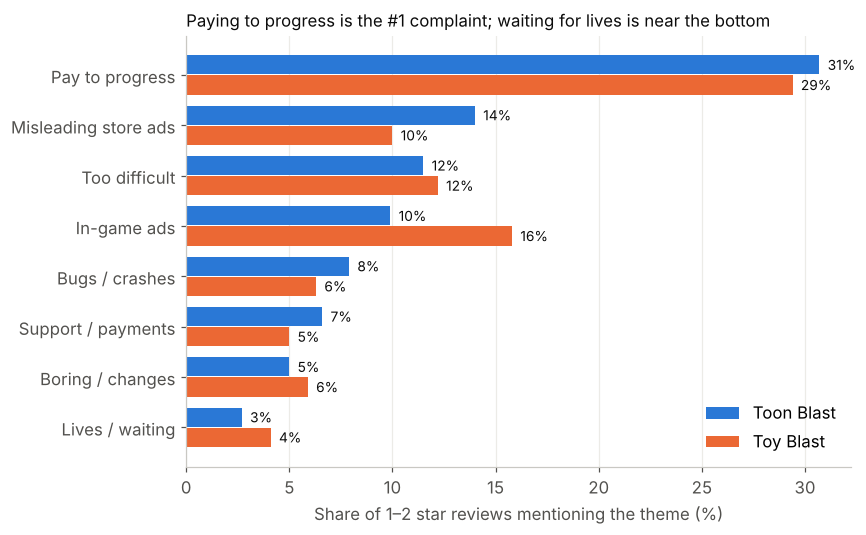

In [8]:
plot = theme_share.iloc[::-1]
y = np.arange(len(plot))
h = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
for i, (game, color) in enumerate([("Toon Blast", BLUE), ("Toy Blast", ORANGE)]):
    bars = ax.barh(y + (0.5 - i) * (h + 0.02), plot[game], h, color=color, label=game)
    for b, v in zip(bars, plot[game]):
        ax.text(v + 0.4, b.get_y() + b.get_height() / 2, f"{v:.0f}%",
                va="center", fontsize=9, color=INK)
ax.set_yticks(y, plot.index)
ax.set_xlabel("Share of 1–2 star reviews mentioning the theme (%)")
ax.xaxis.grid(True, color="#ecebe7"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Paying to progress is the #1 complaint; waiting for lives is near the bottom",
             loc="left", color=INK, fontsize=11)
plt.tight_layout()
plt.savefig("images/complaint_themes.png", dpi=160)
plt.show()

**Key takeaways**
- **"I have to pay to progress" is by far the biggest complaint** (~30% of negative reviews in both games), followed by levels feeling too difficult.
- **Waiting for lives is one of the smallest themes (3–4%).** Players seem to accept breaks. What frustrates them is feeling *forced to pay* at hard levels. This fits the Cookie Cats result: a break by itself didn't hurt retention.
- Toy Blast's negative reviews mention in-game ads more; Toon Blast's mention misleading store ads more.

*Note: Toy Blast has only ~220 negative reviews in this window, so its percentages are less precise.*

## 4. Deep dives

### 4a. When rewarded ads fail
Many "lives" and "ads" complaints are not about waiting. They're about **rewarded ads not working**: the player wants to watch an ad for extra moves or lives, but the ad isn't ready, the game freezes or the reward never arrives. And this often happens right when the player is about to beat a level.

In [9]:
rewarded_fail = (df["lower"].str.contains(r"\bads?\b", regex=True)
                 & df["lower"].str.contains(r"(?:not ready|freez|didn.?t (?:get|give)|not giv|no lives|nothing happen|doesn.?t give|did not get|never (?:get|got)|black screen|stuck)", regex=True))
print("Reviews describing failed rewarded ads:", rewarded_fail.sum(),
      "| average rating:", round(df.loc[rewarded_fail, "score"].mean(), 2))
for text in df.loc[rewarded_fail, "text"].sample(4, random_state=1):
    print(" •", text[:140].replace("\n", " "))

Reviews describing failed rewarded ads: 67 | average rating: 2.31
 • often ads are not ready and can't get free moves. will let you see 1 of 3 msgs and freeze up. game will lock up and lose position and status
 • have had the game for years and love it. recently the game consistently freezes after you attempt to watch an ad after you have gotten the s
 • WAS a great game. Now you don't get ads to earn extra moves to beat hard levels. You're stuck on a level that happens to have one less move 
 • Every time I have the bonus and decide to watch an ad to win the game, the game freezes and I lose my ability to use the bonus that I got fr


This is a double loss for Peak: the ad impression (revenue) is lost, *and* the player gets angry at the exact moment they were willing to engage. It is likely a technical or ad-network issue, so it may be one of the cheapest problems to fix.

### 4b. Does getting stuck lead to quitting?

In [10]:
stuck = df["lower"].str.contains(r"(?:stuck|same level|for (?:days|weeks|a week|a month)|tried \d+ times|\d+ (?:tries|attempts)|hundreds? of times|can.?t (?:get past|pass|beat)|cannot (?:get past|pass|beat))", regex=True)
quits = df["lower"].str.contains(r"(?:uninstall\w*|delet\w*|quit\w*|giv\w* up|gave up|stop\w* playing|done with|leaving)", regex=True)
negative = df["score"] <= 2
print("Reviews about being stuck on a level:", stuck.sum(), "| average rating:", round(df.loc[stuck, "score"].mean(), 2))
print(f"Mention quitting -> stuck reviews: {quits[stuck].mean():.0%} | other negative reviews: {quits[~stuck & negative].mean():.0%}")

Reviews about being stuck on a level: 103 | average rating: 2.23
Mention quitting -> stuck reviews: 19% | other negative reviews: 14%


Players who say they're stuck mention quitting more often (19% vs 14%). The sample is small (~100 reviews), so this is a **supporting signal, not proof**.

### 4c. Why does Toon Blast rate lower?

In [11]:
mislead_share = (same.groupby("game")["Misleading store ads"].mean() * 100).round(1)
print("Share of all reviews about misleading store ads (%):", mislead_share.to_dict())
print("Average rating:", same.groupby("game")["score"].mean().round(2).to_dict())
print("Average rating without those reviews:",
      same[~same["Misleading store ads"]].groupby("game")["score"].mean().round(2).to_dict())

Share of all reviews about misleading store ads (%): {'Toon Blast': 3.8, 'Toy Blast': 1.7}
Average rating: {'Toon Blast': 3.91, 'Toy Blast': 4.31}
Average rating without those reviews: {'Toon Blast': 4.0, 'Toy Blast': 4.35}


Toon Blast has twice as many "this isn't the game in the ad" reviews, which often come from brand-new players. But removing them only moves Toon Blast from 3.91 to 4.00, so they explain **only a small part** of the gap. The rest is an open question.

## 5. Product ideas

### Idea 1: Fix rewarded-ad reliability
The cheapest win. Track the rewarded-ad failure rate (not ready / freeze / no reward) as a metric, especially on hard levels.

### Idea 2: Free extra moves after repeated failures
If a player fails the same level many times, they are at risk of quitting. A few free moves at that moment could keep them in the game. Since paying to progress is a key revenue source, the goal is **occasional help, not removing the paywall**.

**Risk:** if players learn "fail 5 times and I get free moves", some will stop paying and just wait. To limit this:
- don't use a fixed, announced threshold (e.g. vary it between 5 and 8 failures);
- target the help to players who have never paid and are at risk of churning, not to regular payers.

| | How I would test it |
|---|---|
| **Groups** | Control vs. free moves after 5 failures vs. after 10 failures |
| **Primary metric** | Churn on hard levels, D7/D30 retention |
| **Decision metric** | Revenue per install (D30/D90 LTV), across *all* players |
| **Guardrail** | Payer conversion and coin purchase rate must not drop |

### Idea 3 (considered): A paid "skip level" option
Some frustrated players who already spend money might happily pay to skip a level. But as a standalone purchase it has real risks:
- **It could confirm the #1 complaint:** "they make levels hard so we pay to skip".
- **Content runs out faster:** Peak ships new levels every two weeks, and skippers reach the end sooner and then wait.
- **It may cannibalize revenue:** one skip could replace several "+5 moves" purchases.
- **Fairness:** it would affect team events and leaderboards.

None of the 10,000 reviews asked for a level skip, but players rarely ask for features they haven't seen, so only an experiment can answer this.

**Middle ground:** add it as a **limited perk inside the existing Toy Pass** (e.g. one skip per season). It stays scarce, doesn't burn content, avoids a "pay to win" image and gives players one more reason to buy the pass.

## 6. Limitations

- **Reviewers are not all players.** People who write reviews are mostly very happy or very angry.
- **Keyword rules are rough.** I validated them by reading samples, but some reviews will be missed or mis-tagged, and about a third of negative reviews don't match any theme.
- **Only English reviews from the US store,** and only the most recent 5,000 per game.
- Results show **what players say**, not what they do. The ideas above need A/B tests to confirm.